Імпорт бібліотек та завантаження даних

In [ ]:
import pandas as pd
import urllib.request
import urllib.parse
import matplotlib.pyplot as plt
import seaborn as sns

# Формуємо безпечний URL
url = "https://uk.wikipedia.org/wiki/" + urllib.parse.quote("Населення_України")

# Додаємо заголовки браузера, щоб Wikipedia не блокувала запит (403 Forbidden)
req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
html_content = urllib.request.urlopen(req).read().decode('utf-8')

# Зчитуємо таблицю за допомогою pandas із завантаженого HTML
df = pd.read_html(html_content, match="Коефіцієнт народжуваності")[0]

/tmp/ipykernel_1527/867685975.py:15: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  df = pd.read_html(html_content, match="Коефіцієнт народжуваності")[0]


Огляд даних

In [ ]:
df.head()


,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,230.0,206.0,160.0,130,73,126,—,—
1,Вінницька,224.0,192.0,142.0,124,84,112,109,76
2,Волинська,247.0,250.0,179.0,153,112,148,141,101
3,Дніпропетровська,204.0,204.0,151.0,123,71,112,111,71
4,Донецька,271.0,214.0,140.0,109,61,98,82,—


In [ ]:
df.describe()

,1950,1960,1970,1990,2000,2012
count,26.000000,27.000000,27.000000,28.000000,28.000000,28.000000
mean,230.923077,207.481481,155.851852,130.428571,82.071429,116.464286
std,28.220451,29.360322,18.703565,15.278716,15.568079,16.362745
min,186.000000,163.000000,127.000000,108.000000,61.000000,94.000000
25%,211.500000,186.500000,144.000000,122.250000,70.750000,104.500000
50%,226.000000,204.000000,152.000000,126.000000,78.500000,114.500000
75%,246.000000,220.500000,163.000000,140.500000,89.500000,122.500000
max,314.000000,273.000000,207.000000,168.000000,118.000000,159.000000


Очищення

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.dtypes

,0
Регіон,object
1950,float64
1960,float64
1970,float64
1990,int64
2000,int64
2012,int64
2014,object
2019,object


In [ ]:
for col in df.columns[1:]:
    # Заменяем запятые на точки для корректного считывания дробей
    df[col] = df[col].astype(str).str.replace(',', '.')

    # Превращаем в числовой формат (ошибки/буквы станут NaN)
    df[col] = pd.to_numeric(df[col], errors='coerce')

df.dtypes

,0
Регіон,object
1950,float64
1960,float64
1970,float64
1990,int64
2000,int64
2012,int64
2014,float64
2019,float64


In [ ]:
df.isna().sum()

,0
Регіон,0
1950,2
1960,1
1970,1
1990,0
2000,0
2012,0
2014,0
2019,0


In [ ]:
df_indexed = df_indexed.interpolate(method='linear', axis=1, limit_direction='both')

df_indexed.isnull().sum()

,0
1950,0
1960,0
1970,0
1990,0
2000,0
2012,0
2014,0
2019,0


In [ ]:
df_indexed.describe()


,1950,1960,1970,1990,2000,2012,2014,2019
count,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000
mean,225.107143,204.535714,154.750000,130.428571,82.071429,116.464286,112.250000,82.285714
std,35.183476,32.757789,19.257755,15.278716,15.568079,16.362745,19.610324,18.512973
min,125.000000,125.000000,125.000000,108.000000,61.000000,94.000000,51.000000,51.000000
25%,207.250000,183.750000,143.500000,122.250000,70.750000,104.500000,104.750000,68.000000
50%,222.000000,201.000000,151.500000,126.000000,78.500000,114.500000,112.000000,79.500000
75%,244.000000,219.250000,161.500000,140.500000,89.500000,122.500000,121.250000,89.000000
max,314.000000,273.000000,207.000000,168.000000,118.000000,159.000000,148.000000,126.000000


In [ ]:
df_indexed = df_indexed / 10

df_indexed.describe()

,1950,1960,1970,1990,2000,2012,2014,2019
count,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000
mean,22.510714,20.453571,15.475000,13.042857,8.207143,11.646429,11.225000,8.228571
std,3.518348,3.275779,1.925775,1.527872,1.556808,1.636274,1.961032,1.851297
min,12.500000,12.500000,12.500000,10.800000,6.100000,9.400000,5.100000,5.100000
25%,20.725000,18.375000,14.350000,12.225000,7.075000,10.450000,10.475000,6.800000
50%,22.200000,20.100000,15.150000,12.600000,7.850000,11.450000,11.200000,7.950000
75%,24.400000,21.925000,16.150000,14.050000,8.950000,12.250000,12.125000,8.900000
max,31.400000,27.300000,20.700000,16.800000,11.800000,15.900000,14.800000,12.600000


1. Загальнонаціональний тренд: Як змінювався загальний тренд народжуваності в Україні з 1950 по 2019 рік?

2. Регіональні лідери та аутсайдери: Які регіони є лідерами, а які аутсайдерами за показником народжуваності у 2019 році?

3. Динаміка за регіонами: Як виглядає динаміка народжуваності в розрізі ключових регіонів за роками (теплова карта)?

4. Порівняння макрорегіонів: Яка різниця між середніми показниками західних та східно-північних регіонів?

5. Зміна розподілу: Як змінився розкид (дисперсія) значень між регіонами (порівняння розподілу на початку та в кінці періоду)?

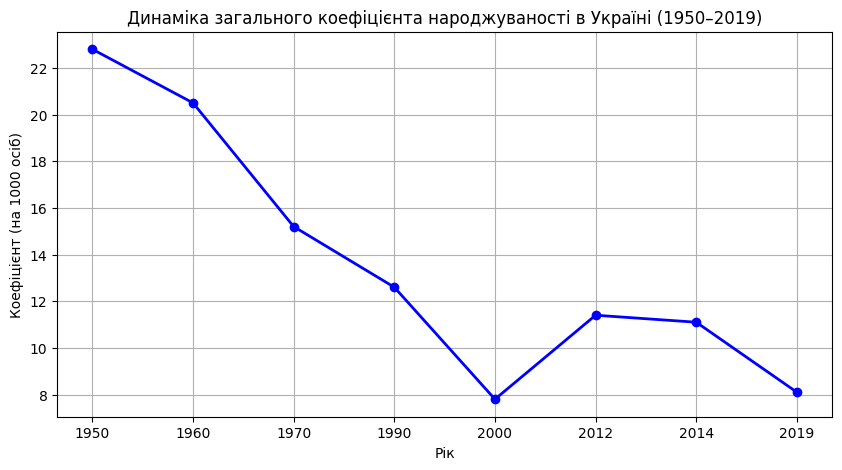

In [ ]:
plt.figure(figsize=(10, 5))
df_indexed.loc['Україна'].astype(float).plot(kind='line', marker='o', color='b', linewidth=2)
plt.title("Динаміка загального коефіцієнта народжуваності в Україні (1950–2019)")
plt.xlabel("Рік")
plt.ylabel("Коефіцієнт (на 1000 осіб)")
plt.grid(True)
plt.savefig("chart1.png")
plt.show()

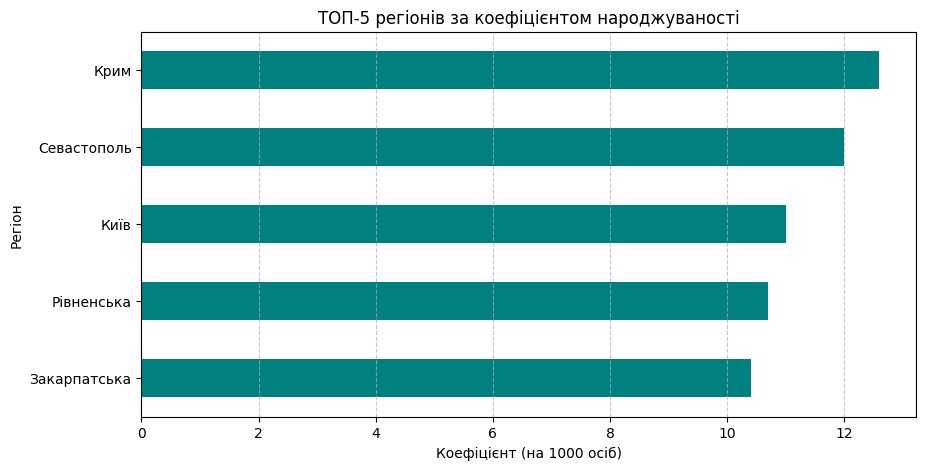

In [ ]:
plt.figure(figsize=(10, 5))
df_indexed.iloc[:, -1].astype(float).nlargest(5).plot(kind='barh', color='teal')
plt.title("ТОП-5 регіонів за коефіцієнтом народжуваності")
plt.xlabel("Коефіцієнт (на 1000 осіб)")
plt.ylabel("Регіон")
plt.gca().invert_yaxis()  # Ставимо лідера нагору
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.savefig("chart2.png")
plt.show()

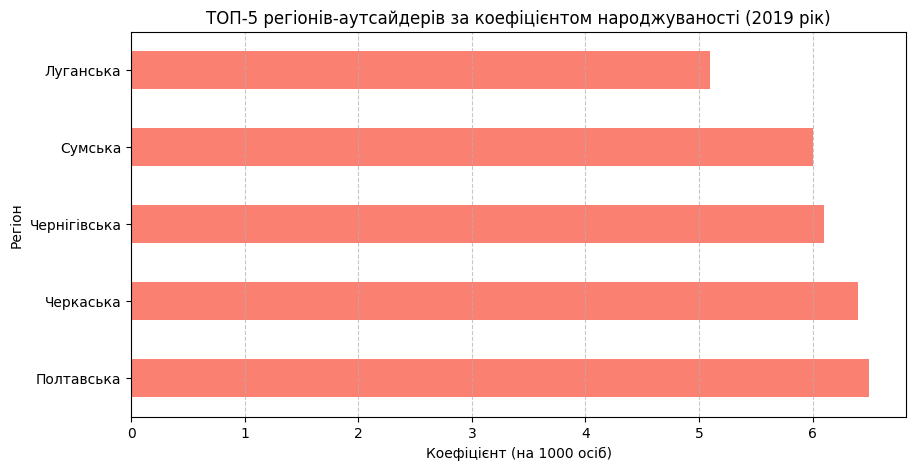

In [ ]:
plt.figure(figsize=(10, 5))
df_indexed.iloc[:, -1].astype(float).nsmallest(5).plot(kind='barh', color='salmon')
plt.title("ТОП-5 регіонів-аутсайдерів за коефіцієнтом народжуваності (2019 рік)")
plt.xlabel("Коефіцієнт (на 1000 осіб)")
plt.ylabel("Регіон")
plt.gca().invert_yaxis()  # Ставимо найнижчий показник нагору для зручності
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.savefig("chart2_bottom.png")
plt.show()

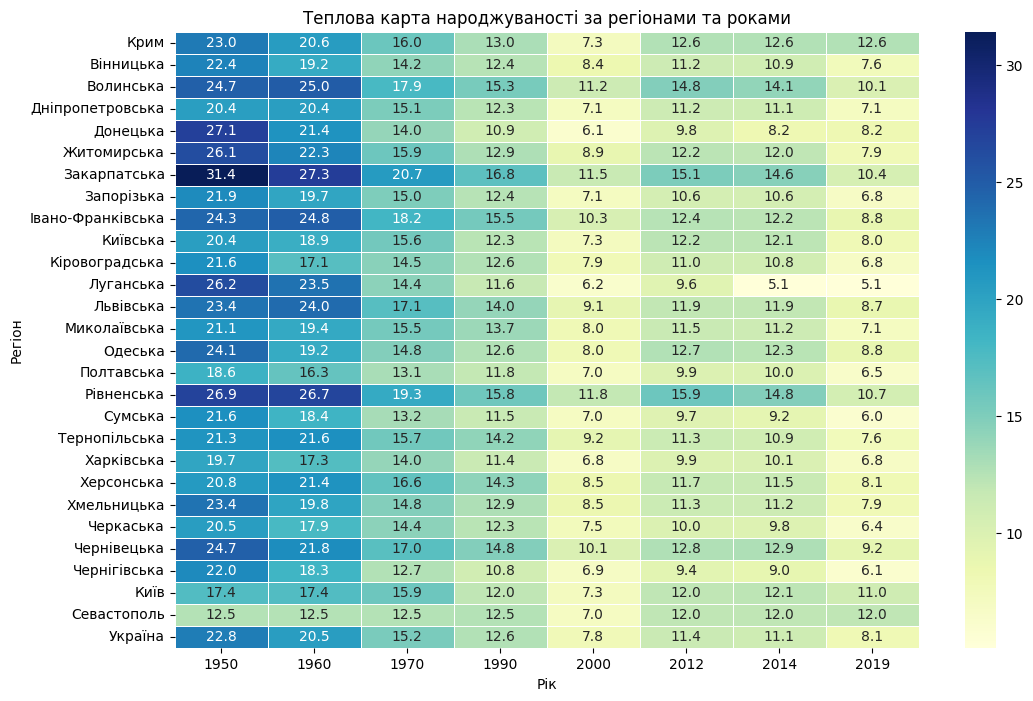

In [ ]:
plt.figure(figsize=(12, 8))
sns.heatmap(df_indexed.astype(float), cmap="YlGnBu", annot=True, fmt=".1f", linewidths=.5)
plt.title("Теплова карта народжуваності за регіонами та роками")
plt.xlabel("Рік")
plt.ylabel("Регіон")
plt.savefig("chart3.png")
plt.show()

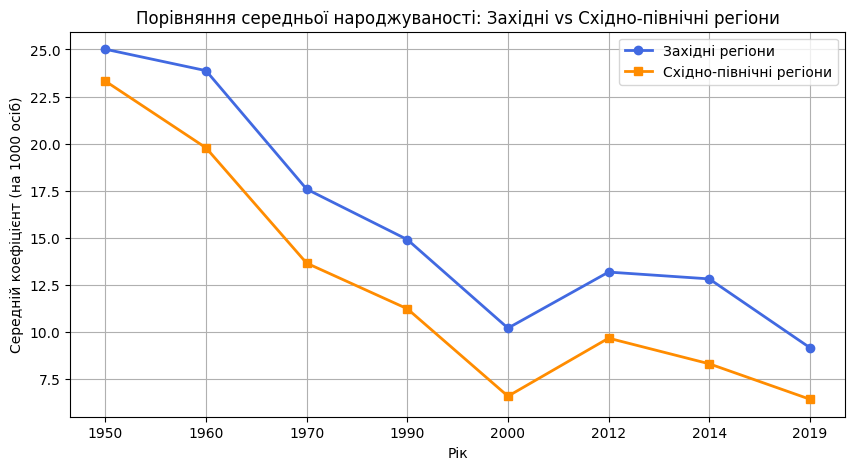

In [ ]:
west_regions = [
    'Волинська',
    'Закарпатська',
    'Івано-Франківська',
    'Львівська',
    'Рівненська',
    'Тернопільська',
    'Хмельницька',
    'Чернівецька',
]

east_north_regions = [
    'Харківська',
    'Луганська',
    'Донецька',
    'Сумська',
    'Чернігівська',
]

west_mean = (
    df_indexed.loc[df_indexed.index.isin(west_regions)].astype(float).mean()
)
east_north_mean = (
    df_indexed.loc[df_indexed.index.isin(east_north_regions)]
    .astype(float)
    .mean()
)

plt.figure(figsize=(10, 5))
west_mean.plot(
    label='Західні регіони', color='royalblue', linewidth=2, marker='o'
)
east_north_mean.plot(
    label='Східно-північні регіони',
    color='darkorange',
    linewidth=2,
    marker='s',
)
plt.title(
    'Порівняння середньої народжуваності: Західні vs Східно-північні регіони'
)
plt.xlabel('Рік')
plt.ylabel('Середній коефіцієнт (на 1000 осіб)')
plt.legend()
plt.grid(True)
plt.savefig('chart_macro_comparison.png')
plt.show()

--- Статистика розкиду за 1950 рік ---
Дисперсія: 12.3788
Стандартне відхилення: 3.5183

--- Статистика розкиду за 2019 рік ---
Дисперсія: 3.4273
Стандартне відхилення: 1.8513


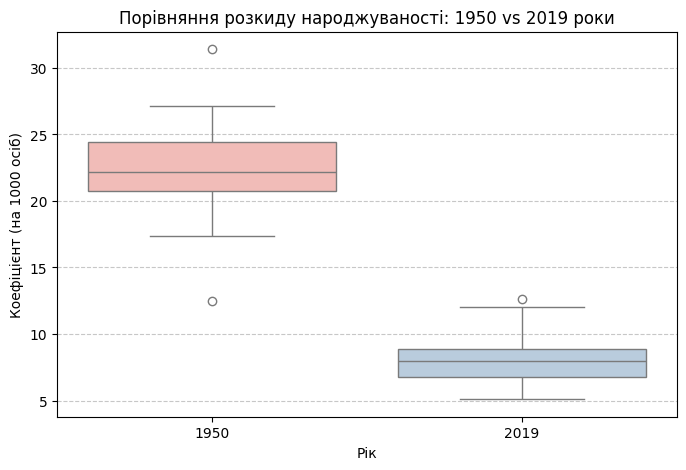

In [ ]:
start_year = df_indexed.columns[0]
end_year = df_indexed.columns[-1]

print(f"--- Статистика розкиду за {start_year} рік ---")
print(f"Дисперсія: {df_indexed[start_year].astype(float).var():.4f}")
print(f"Стандартне відхилення: {df_indexed[start_year].astype(float).std():.4f}")

print(f"\n--- Статистика розкиду за {end_year} рік ---")
print(f"Дисперсія: {df_indexed[end_year].astype(float).var():.4f}")
print(f"Стандартне відхилення: {df_indexed[end_year].astype(float).std():.4f}")

plt.figure(figsize=(8, 5))
sns.boxplot(data=df_indexed[[start_year, end_year]].astype(float), palette="Pastel1")
plt.title(f"Порівняння розкиду народжуваності: {start_year} vs {end_year} роки")
plt.xlabel("Рік")
plt.ylabel("Коефіцієнт (на 1000 осіб)")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig("chart_dispersion.png")
plt.show()